# EN3150 Assignment 03 — Part 3: Optimizer selection and tuning

**Task:** state the optimizer and learning rate you chose and why; compare it with (a) plain SGD and (b) SGD with momentum; explain the effect of the momentum parameter on convergence and performance.

**Experiment:** Model A is trained from the *same initial weights* (fixed seed) and the same data for 20 epochs with each optimizer. Selection is by **validation** accuracy; test accuracy is only reported.

| Run | Optimizer | Learning rate |
|---|---|---|
| Chosen | Adam | 1e-3 |
| (a) | SGD | 0.01 |
| (b) | SGD + momentum 0.9 | 0.01 |
| Extra | Momentum sweep: 0, 0.5, 0.9, 0.99 (+ 0.99 with a smaller lr) | 0.01 |

Estimated time on a CPU laptop: roughly 20 epochs x (3 main runs + 3 extra sweep runs) x Model A epoch time. Set `RUN_SWEEP = False` to skip the sweep while testing.

**Before running:** keep `a03_common.py` in the same folder as this notebook, and run the **Model A notebook first** (it creates `outputs/eurosat_64.npz` and `outputs/splits.npz`, so every model uses the identical 70/15/15 split).

## 1. Setup

In [1]:
from a03_common import *

EPOCHS_OPT = 20
RUN_SWEEP = True
set_seed(SEED)
data = Data(norm="dataset", batch_size=64, augment=True)

def run(name, make_opt, epochs=EPOCHS_OPT, verbose=True):
    set_seed(SEED)                                   # identical initial weights and batch order for every run
    model = ModelA(data.num_classes, 3, IMG_SIZE).to(DEVICE)
    hist = train_model(model, make_opt(model.parameters()), data, epochs, name=name, verbose=verbose)
    ev = evaluate(model, data, verbose=False)
    return {"hist": hist, "test_acc": ev["acc"]}

def epochs_to(hist, thr):
    for i, a in enumerate(hist["val_acc"], 1):
        if a >= thr:
            return i
    return None

def table(results, thr=0.90):
    print(f"{'Run':<34}{'Best val acc':>13}{'Ep to '+str(int(thr*100))+'%':>10}{'Val loss @5':>13}{'Final train loss':>18}{'Test acc':>10}{'s/epoch':>9}")
    for name, r in results.items():
        h = r["hist"]
        e = epochs_to(h, thr)
        print(f"{name:<34}{max(h['val_acc']):>13.4f}{(str(e) if e else 'not hit'):>10}{h['val_loss'][4]:>13.4f}"
              f"{h['train_loss'][-1]:>18.4f}{r['test_acc']:>10.4f}{np.mean(h['epoch_time']):>9.1f}")

## 2. Main comparison: Adam vs SGD vs SGD + momentum
**Why Adam, lr = 1e-3 (the chosen optimizer):**
- Adam keeps running estimates of the gradient mean and squared gradient, giving every parameter its own adaptive step size. It needs little learning-rate tuning, which matters when each experiment costs minutes of CPU time.
- Model A has no normalisation layers, so layers see differently scaled gradients. Adaptive scaling copes with that better than a single global learning rate.
- 1e-3 is the well-tested default for Adam and converges within the 20-25 epoch budget.
- The extra optimizer state (two tensors per weight) exists only during training, so it adds nothing to the deployed model size or inference cost.

The comparison runs below test whether that reasoning holds on this dataset.

In [2]:
RUNS = {
    "Adam (lr=1e-3)":                lambda p: torch.optim.Adam(p, lr=1e-3),
    "SGD (lr=0.01)":                 lambda p: torch.optim.SGD(p, lr=0.01),
    "SGD + momentum 0.9 (lr=0.01)":  lambda p: torch.optim.SGD(p, lr=0.01, momentum=0.9),
}
results = {}
for name, make_opt in RUNS.items():
    results[name] = run(name, make_opt)

[Adam (lr=1e-3)] epoch 01 | train loss 1.1545 acc 0.5728 | val loss 0.7864 acc 0.7178 | 31.0s
[Adam (lr=1e-3)] epoch 02 | train loss 0.7010 acc 0.7510 | val loss 0.7314 acc 0.7338 | 20.5s
[Adam (lr=1e-3)] epoch 03 | train loss 0.5982 acc 0.7942 | val loss 0.6131 acc 0.7874 | 21.2s
[Adam (lr=1e-3)] epoch 04 | train loss 0.4927 acc 0.8334 | val loss 0.4511 acc 0.8452 | 21.0s
[Adam (lr=1e-3)] epoch 05 | train loss 0.4246 acc 0.8564 | val loss 0.3477 acc 0.8802 | 21.8s
[Adam (lr=1e-3)] epoch 06 | train loss 0.3575 acc 0.8805 | val loss 0.3352 acc 0.8864 | 22.0s
[Adam (lr=1e-3)] epoch 07 | train loss 0.3104 acc 0.8974 | val loss 0.3108 acc 0.8877 | 21.5s
[Adam (lr=1e-3)] epoch 08 | train loss 0.2751 acc 0.9084 | val loss 0.2324 acc 0.9227 | 21.8s
[Adam (lr=1e-3)] epoch 09 | train loss 0.2506 acc 0.9158 | val loss 0.2518 acc 0.9104 | 23.0s
[Adam (lr=1e-3)] epoch 10 | train loss 0.2265 acc 0.9259 | val loss 0.2850 acc 0.9086 | 24.2s
[Adam (lr=1e-3)] epoch 11 | train loss 0.2211 acc 0.9273 | v

Run                                Best val acc Ep to 90%  Val loss @5  Final train loss  Test acc  s/epoch
Adam (lr=1e-3)                           0.9437         8       0.3477            0.1234    0.9435     27.7
SGD (lr=0.01)                            0.8040   not hit       1.1052            0.6141    0.8025     28.6
SGD + momentum 0.9 (lr=0.01)             0.9415        11       0.4895            0.1419    0.9494     27.3


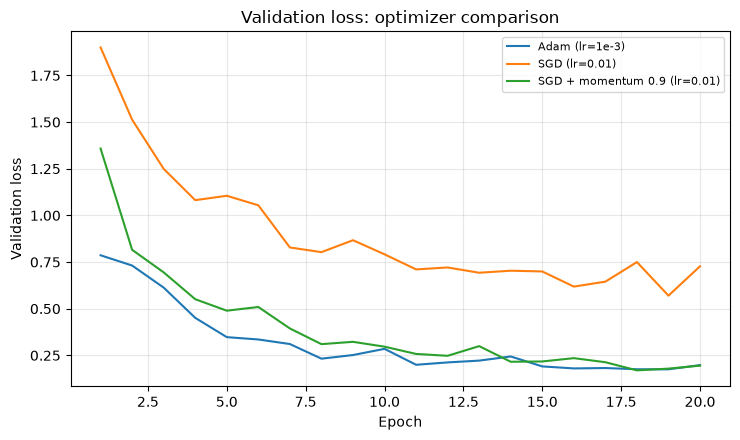

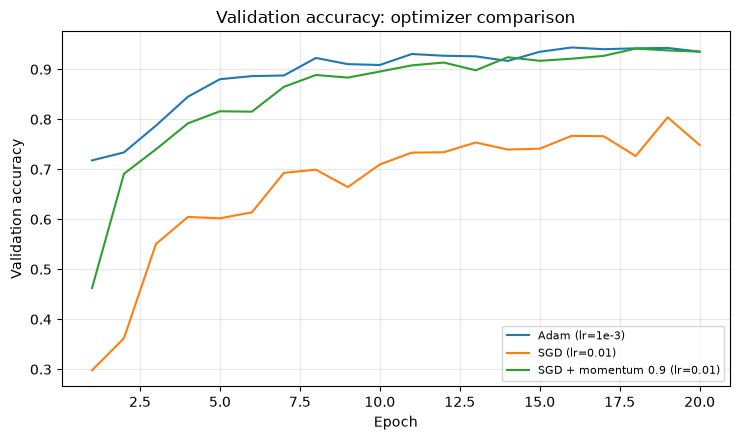

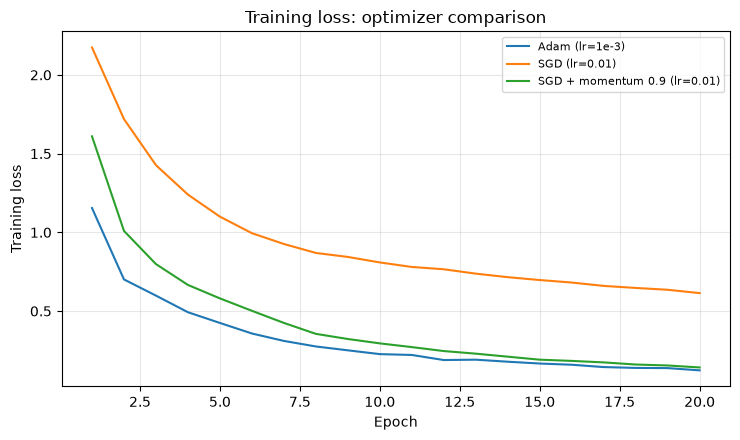

In [3]:
table(results)
hists = {k: v["hist"] for k, v in results.items()}
plot_compare(hists, "val_loss",  "Validation loss",     "Validation loss: optimizer comparison",     "opt_val_loss.png")
plot_compare(hists, "val_acc",   "Validation accuracy", "Validation accuracy: optimizer comparison", "opt_val_acc.png")
plot_compare(hists, "train_loss","Training loss",       "Training loss: optimizer comparison",       "opt_train_loss.png")